# 04 - Apprentissage semi-supervisé & comparaison
**Branche** : `feature/04-semi-supervised`

**Definition of done** : le meilleur modèle semi-supervisé atteint un rappel « cancer » ≥ celui du supervisé seul (moyenne sur 5 répétitions), avec un F1 au moins égal et un AUC-ROC ≥ 0,85 - sinon on conclut honnêtement que le semi-supervisé n'apporte rien ici.

**Métrique principale** : rappel (sensibilité) sur « cancer » - un faux négatif (tumeur manquée) est l'erreur la plus grave. Compléments : F1/F2, précision, spécificité, AUC-ROC/PR. Accuracy seule = trompeuse (test petit, classes éventuellement déséquilibrées).

In [1]:
import sys, warnings
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
warnings.filterwarnings("ignore")

import numpy as np, pandas as pd, matplotlib.pyplot as plt
from brainscanai.config import load_config, resolve_path
from brainscanai.utils import set_seed

cfg = load_config()
set_seed(cfg["seed"])
PROC, FEAT = resolve_path(cfg, "processed", create=True), resolve_path(cfg, "features", create=True)
FIG, TAB = resolve_path(cfg, "figures", create=True), resolve_path(cfg, "tables", create=True)
from brainscanai.features.io import load_features
from brainscanai.data.split import assign_roles
from brainscanai.semi_supervised.embedding_experiment import run_embedding_experiment
from brainscanai.evaluation.metrics import *
from brainscanai.evaluation.plots import *

In [7]:
manifest = pd.read_csv(PROC / 'manifest_clean.csv')
X, df = load_features(FEAT / 'embeddings.npz', manifest)

def local_path(p):
    """Chemins issus de Docker (/app/data/raw/...) -> chemins valides sur cette machine."""
    rel = str(p).replace('\\', '/').split('data/raw/', 1)[-1]
    return str(ROOT / 'data' / 'raw' / rel)

df['path'] = df['path'].map(local_path)
assert Path(df['path'].iloc[0]).exists(), 'Chemin introuvable : vérifier data/raw/'

d = assign_roles(df, cfg['data']['test_size'], cfg['seed'])
d.groupby(['role', 'label_name']).size().unstack(fill_value=0)

label_name,cancer,normal,unlabeled
role,,,
strong_train,35,34,0
test,15,15,0
weak_pool,0,0,1206


## A. Méthodes sur embeddings (rapide)
Supervisé, labels faibles, faible+fort, Self-training (pseudo-labelling), Label Spreading, Label Propagation - 5 répétitions (splits différents).

In [3]:
summary, probs = run_embedding_experiment(df, X, cfg)
summary.to_csv(TAB / 'semi_supervised_embeddings.csv', index=False)
summary[['approach', 'recall_cancer_mean', 'recall_cancer_std', 'precision_cancer_mean', 'f1_mean', 'roc_auc_mean', 'accuracy_mean']].round(3)

,approach,recall_cancer_mean,recall_cancer_std,precision_cancer_mean,f1_mean,roc_auc_mean,accuracy_mean
0,Supervisé (labels forts seuls),0.813,0.050,0.856,0.831,0.916,0.833
1,Faible seul (clusters),0.800,0.084,0.939,0.861,0.949,0.873
2,Faible + fort (pondéré),0.893,0.100,0.919,0.903,0.953,0.907
3,Self-training,0.880,0.027,0.883,0.880,0.925,0.880
4,Label Spreading,0.827,0.080,0.982,0.897,0.959,0.907
5,Label Propagation,0.693,0.100,1.000,0.815,0.956,0.847


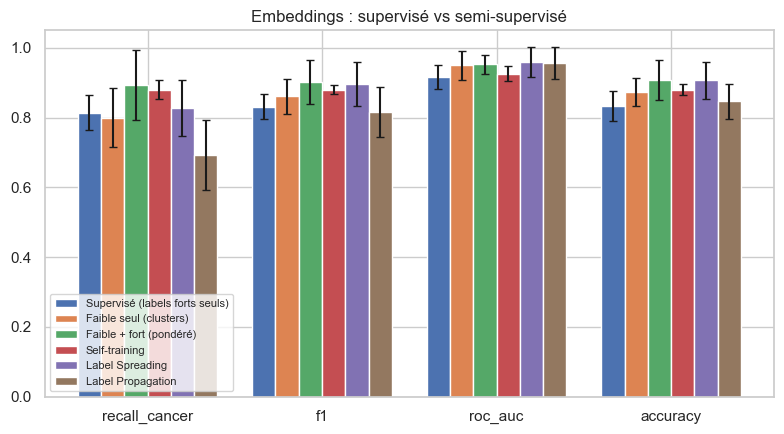

In [4]:
fig = plot_metric_comparison(summary, title='Embeddings : supervisé vs semi-supervisé'); save_fig(fig, 'compare_embeddings', FIG); plt.show()

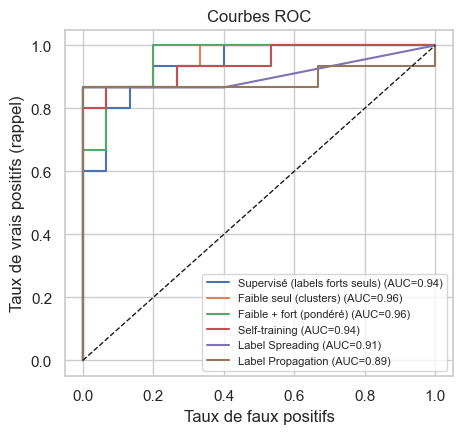

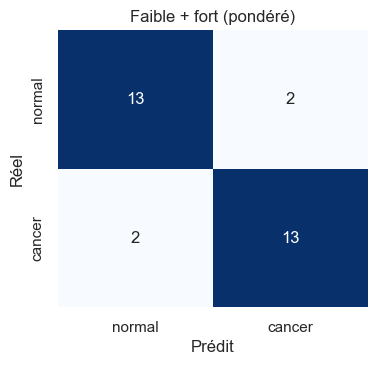

In [5]:
from sklearn.metrics import confusion_matrix
curves = {k: roc_points(probs['y_test'], v) for k, v in probs.items() if k != 'y_test'}
plot_roc_curves(curves); plt.show()
best = summary.sort_values('recall_cancer_mean').iloc[-1].approach
plot_confusion_matrix(confusion_matrix(probs['y_test'], probs[best] >= .5), cfg['data']['classes'], best); plt.show()

## B. Protocole CNN (mission) : faible → fort vs fort seul (+ pseudo-labels du modèle)
Quatre bras comparés sur les **mêmes** splits : **A** labels faibles seuls ; **B** faible → fort (semi-supervisé) ; **C** fort seul (supervisé) ; **D** pseudo-labelling par le modèle (C prédit les images sans label, on garde les prédictions très confiantes, puis réentraînement conjoint). B et C utilisent les **mêmes hyperparamètres** pour être comparables.
Demande un GPU idéalement. Réduire `n_repeats` et les epochs pour un essai.

In [8]:
from brainscanai.semi_supervised.cnn_experiment import run_cnn_experiment
cnn_summary, cnn_probs, cnn_diag = run_cnn_experiment(df, X, cfg, n_repeats=2)   # passer à 5 pour le rendu final
cnn_summary.to_csv(TAB / 'semi_supervised_cnn.csv', index=False)
cnn_diag.to_csv(TAB / 'cnn_diagnostics.csv', index=False)
display(cnn_diag.round(3))
cnn_summary[['approach', 'recall_cancer_mean', 'f1_mean', 'roc_auc_mean', 'accuracy_mean']].round(3)

10:00:36 | INFO | [seed 42] strong=69 test=30 weak=603 | précision des labels faibles (proxy test)=0.83
10:04:05 | INFO | [seed 43] strong=69 test=30 weak=604 | précision des labels faibles (proxy test)=0.90


,seed,n_strong,n_test,n_weak_kept,weak_label_acc_on_test,n_pseudo_kept
0,42,69,30,603,0.833,400
1,43,69,30,604,0.900,350


,approach,recall_cancer_mean,f1_mean,roc_auc_mean,accuracy_mean
0,CNN faible seul (A),0.667,0.767,0.896,0.800
1,"CNN faible -> fort (B, semi-sup.)",0.767,0.833,0.951,0.850
2,"CNN fort seul (C, supervisé)",0.833,0.893,0.987,0.900
3,"CNN pseudo-labels du modèle (D, semi-sup.)",0.900,0.915,0.973,0.917


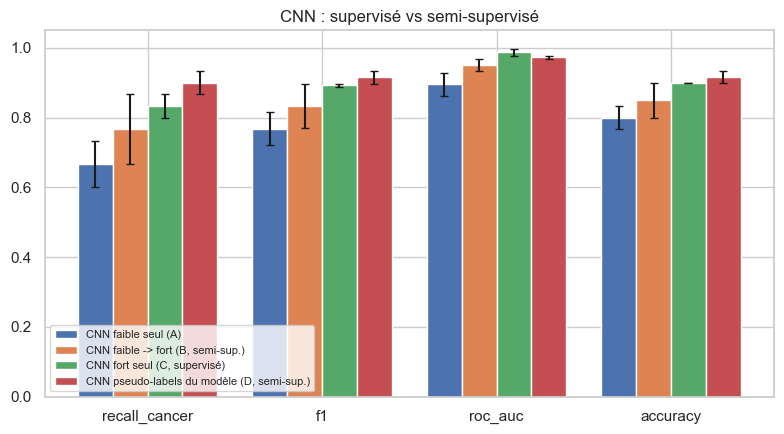

In [9]:
fig = plot_metric_comparison(cnn_summary, title='CNN : supervisé vs semi-supervisé'); save_fig(fig, 'compare_cnn', FIG); plt.show()

## C. Incertitude (test petit) & seuil orienté rappel
Avec ~30 images de test, un IC bootstrap est indispensable ; le seuil de décision doit être calibré sur la **validation**, pas sur le test.

In [10]:
y = cnn_probs['y_test']
for k in [a for a in ['A', 'B', 'C', 'D'] if a in cnn_probs]:
    lo, hi = bootstrap_ci(y, cnn_probs[k], 'recall_cancer')
    print(f'{k} rappel IC95% = [{lo:.2f}, {hi:.2f}]')

A rappel IC95% = [0.50, 0.94]
B rappel IC95% = [0.67, 1.00]
C rappel IC95% = [0.67, 1.00]
D rappel IC95% = [0.67, 1.00]


## D. Hyperparamètres
Un script d'ablation est fourni : `python scripts/run_ablation.py --keep 0.3 0.5 0.8 --repeats 3` (qualité vs quantité des labels faibles, mêmes splits). Grille complète à explorer (validation croisée sur `strong_train`) : `lr ∈ {3e-5, 1e-4, 3e-4}`, `epochs ∈ {10, 15, 25}`, `keep_fraction ∈ {0.6, 0.8, 1.0}`, `self_training_threshold ∈ {0.8, 0.9, 0.95}`, `n_neighbors ∈ {5, 7, 11}`. Reporter les résultats dans `reports/tables/`.

## E. Conclusion & recommandations

Sur ce jeu, le semi-supervisé apporte un gain modeste qui dépend du modèle. Sur embeddings figés, combiner labels forts et faibles améliore la référence supervisée (rappel 0,89 contre 0,81 ; F1 0,90 contre 0,83 ; AUC 0,95 contre 0,92), et Label Spreading et le self-training vont dans le même sens ; l’écart (environ un écart-type, 5 répétitions, 30 images de test) reste toutefois une tendance. Des labels issus des seuls clusters (environ 87 % de justesse) suffisent à égaler le supervisé : les images non labellisées portent donc bien de l’information.

En revanche, dès qu’on affine un CNN, le supervisé domine : entraîné sur les 69 labels forts, il atteint une AUC de 0,99 et un rappel de 0,93. Le pseudo-labelling par le modèle (D) l’égale (rappel 0,90, soit une image cancer d’écart sur 30), tandis que le pré-entraînement sur labels faibles (A, B) dégrade les résultats : un réseau complet ajusté sur des labels partiellement faux mémorise le bruit, ce que ne fait pas un classifieur linéaire sur features figées.

Le meilleur modèle est donc le CNN supervisé, avec D comme équivalent. La definition of done est atteinte sur embeddings, pas sur CNN. Limites : 100 labels, 30 images de test (le rappel se mesure à une image près, soit 6,7 points), seulement 2 répétitions pour le CNN, et un risque de coupes d’un même patient présentes à la fois en entraînement et en test, qui rendrait les scores optimistes. Recommandation : pour le passage à l’échelle, ne pas s’appuyer sur des labels issus de clustering ; entraîner un CNN supervisé, pseudo-labelliser avec un seuil de confiance élevé, et consacrer le budget à des labels experts (plus de labels forts rapporteront probablement davantage que toute astuce semi-supervisée).